<a href="https://colab.research.google.com/github/lucas-estanislau/pe-de-meia/blob/main/01-coleta-pdm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pé-de-Meia**
### e sua relação com a permanência e o desempenho escolar no ensino médio no Brasil

In [ ]:
import pandas as pd
import numpy as np
import requests
import zipfile
from io import BytesIO

In [ ]:
mar24 = "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202403"

# Visulizando os dados do mês de março de 2024 para explorar

response = requests.get(mar24, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as zip_ref:
  arquivo = zip_ref.namelist()[0]

  with zip_ref.open(arquivo) as csv:
    df = pd.read_csv(csv, sep=";", encoding="latin1")

df.head()

/tmp/ipykernel_940/105445487.py:12: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv, sep=";", encoding="latin1")


,MÊS FOLHA,MÊS REFERÊNCIA,UF,CÓDIGO MUNICÍPIO SIAFI,NOME MUNICÍPIO,NIS BENEFICIÁRIO,CPF BENEFICIÁRIO,NOME BENEFICIÁRIO,NIS RESPONSÁVEL,CPF RESPONSÁVEL,NOME RESPONSÁVEL,CÓDIGO TIPO INCENTIVO,TIPO INCENTIVO,PERÍODO INCENTIVO,CÓDIGO ETAPA ENSINO,ETAPA ENSINO,DATA DO PAGAMENTO,VALOR PARCELA
0,202403,202403,AC,643,ACRELANDIA,2.126185e+10,***.408.142-**,ALLAN JHONATA DA SILVA HERMOGENES,1.624864e+10,***.338.912-**,IRACILDA HERMOGENES DE SOUZA FERREIRA,1,Matrícula,Ano letivo 2024,27,3º ano - Ensino Médio Regular,26/03/2024,"200,00"
1,202403,202403,AC,643,ACRELANDIA,2.120773e+10,***.655.722-**,BIANCA DA SILVA RIBEIRO,1.609672e+10,***.872.892-**,ANTONIA ROSEMIRA SANTOS DA SILVA,1,Matrícula,Ano letivo 2024,27,3º ano - Ensino Médio Regular,02/04/2024,"200,00"
2,202403,202403,AC,643,ACRELANDIA,2.380363e+10,***.379.332-**,DAYANE CARVALHO DA SILVA,2.102097e+10,***.323.582-**,ANGELA MARIA CARVALHO,1,Matrícula,Ano letivo 2024,27,3º ano - Ensino Médio Regular,03/04/2024,"200,00"
3,202403,202403,AC,643,ACRELANDIA,2.122791e+10,***.703.662-**,DEBORA DANTAS DE LIMA,2.122791e+10,***.703.662-**,DEBORA DANTAS DE LIMA,1,Matrícula,Ano letivo 2024,25,1º ano - Ensino Médio Regular,03/04/2024,"200,00"
4,202403,202403,AC,643,ACRELANDIA,2.362701e+10,***.319.892-**,DENNIS BOONE DE CARVALHO,2.093918e+10,***.434.512-**,NELSI BOONE,1,Matrícula,Ano letivo 2024,45,EJA - Educação de Jovens e Adultos,28/03/2024,"200,00"


In [ ]:
df.shape

(2416252, 18)

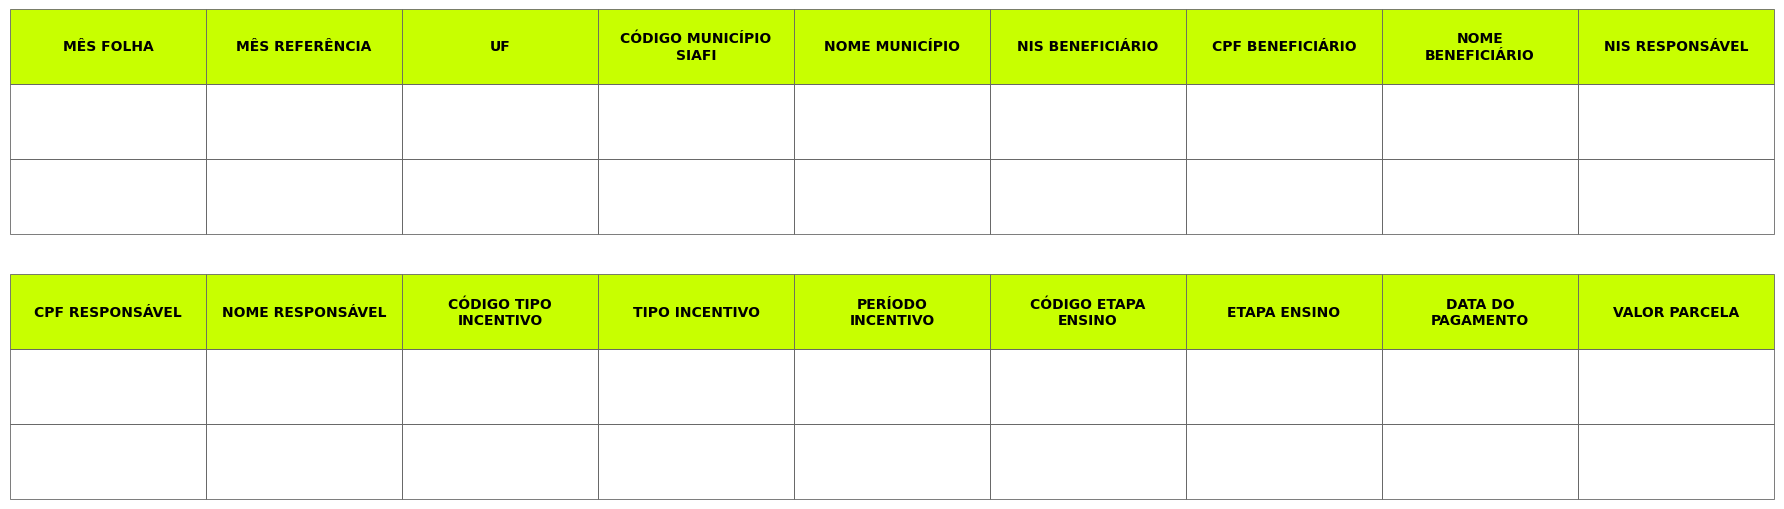

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import matplotlib.pyplot as plt
import textwrap
from google.colab import files

VERDE = "#C8FF00"
BRANCO = "#FFFFFF"
TRANSPARENTE = (0, 0, 0, 0)

# Seleciona duas linhas da base original
amostra = df.head(2).copy()

# Oculta informações pessoais
termos_sensiveis = [
    "NOME", "CPF", "NIS", "BENEFICIARIO",
    "BENEFICIÁRIO", "RESPONSAVEL", "RESPONSÁVEL"
]

for coluna in amostra.columns:
    if any(t in str(coluna).upper() for t in termos_sensiveis):
        amostra[coluna] = "••••"

amostra = amostra.fillna("—").astype(str)

# Mantém todas as colunas em dois blocos
meio = (len(amostra.columns) + 1) // 2
blocos = [
    amostra.iloc[:, :meio],
    amostra.iloc[:, meio:]
]

fig, eixos = plt.subplots(
    2, 1,
    figsize=(18, 5),
    facecolor=TRANSPARENTE
)

fig.subplots_adjust(
    left=0.01, right=0.99,
    top=0.99, bottom=0.01,
    hspace=0.18
)

for ax, bloco in zip(eixos, blocos):
    ax.axis("off")
    ax.set_facecolor(TRANSPARENTE)

    cabecalhos = [
        "\n".join(textwrap.wrap(str(c), 16))
        for c in bloco.columns
    ]

    valores = [
        [
            "\n".join(textwrap.wrap(str(v), 18)[:3])
            for v in linha
        ]
        for linha in bloco.values
    ]

    tabela = ax.table(
        cellText=valores,
        colLabels=cabecalhos,
        cellLoc="center",
        colLoc="center",
        bbox=[0, 0, 1, 1]
    )

    tabela.auto_set_font_size(False)
    tabela.set_fontsize(10)

    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_edgecolor("#666666")
        celula.set_linewidth(0.6)

        if linha == 0:
            celula.set_facecolor(VERDE)
            celula.get_text().set_color("#000000")
            celula.get_text().set_weight("bold")
        else:
            celula.set_facecolor(TRANSPARENTE)
            celula.get_text().set_color(BRANCO)

arquivo = "tabela_pe_de_meia_transparente.png"

plt.savefig(
    arquivo,
    dpi=300,
    transparent=True,
    bbox_inches="tight",
    pad_inches=0
)

plt.show()
files.download(arquivo)


In [ ]:
df.isna().sum()

,0
MÊS FOLHA,0
MÊS REFERÊNCIA,0
UF,0
CÓDIGO MUNICÍPIO SIAFI,0
NOME MUNICÍPIO,0
NIS BENEFICIÁRIO,2147264
CPF BENEFICIÁRIO,2147193
NOME BENEFICIÁRIO,0
NIS RESPONSÁVEL,158758
CPF RESPONSÁVEL,158192


Há 2.147.193 dados ausentes no campo "CPF BENEFICIÁRIO". Ao observar o dataframe, percebe-se que os valores NaN nesse campo possuem o campo "NOME BENEFICIÁRIO" contendo  "*** BENEFICIÁRIO MENOR DE 18 ANOS ***"

In [ ]:
# Conferindo valores possíveis quando o campo "CPF BENENFICIÁRIO" é NaN
df.loc[
    df['CPF BENEFICIÁRIO'].isna(),
    'NOME BENEFICIÁRIO'
].value_counts()

,count
NOME BENEFICIÁRIO,
*** BENEFICIÁRIO MENOR DE 18 ANOS ***,2147193


Esse resultado mostra que todos os valores ausentes no campo de CPF refere-se a beneficiários menores de 18 anos.

In [ ]:
# Verificando os tipos de incentivos existentes
df['TIPO INCENTIVO'].value_counts()

,count
TIPO INCENTIVO,
Matrícula,2416252


In [ ]:
df['VALOR PARCELA'].value_counts()

,count
VALOR PARCELA,
"200,00",2416252


Com isso, é possível concluir que todos os dados de março de 2024 são com incentivo a MATRÍCULA com valor de 200,00 por pagamento.

In [ ]:
# Verificando quantidade de linhas duplicadas
df.duplicated().sum()

np.int64(106641)

In [ ]:
df.loc[df.duplicated(), 'CPF BENEFICIÁRIO'].isna().value_counts()

,count
CPF BENEFICIÁRIO,
True,106641


Todas as 106.641 linhas identificadas como duplicadas pertencem a registros de beneficiários com CPF ausente.

Total de registros: 2.416.251

Registros com CPF ausente: 2.147.193

Linhas identificadas como duplicadas: 106.641

Linhas duplicadas com CPF ausente: 106.641

Linhas duplicadas com CPF preenchido: 0

Com isso, a quantidade de pagamentos pode ser uma aproximação da quantidade de beneficiários atendidos naquele período, mas não é possível afirmar que são exatamente iguais. Portanto, não podemos descartar estas duplicatas.

#Processamento

In [ ]:
# Carrega os dados zipados de cada mês do programa dentro do Portal da Transparência
def carregar_mes(url):
  response = requests.get(url, timeout=120)
  response.raise_for_status()

  with zipfile.ZipFile(BytesIO(response.content)) as zip_ref:
      arquivo = zip_ref.namelist()[0]

      with zip_ref.open(arquivo) as csv:
          df = pd.read_csv(csv, sep=";", encoding="latin1", usecols=["UF", "TIPO INCENTIVO", "VALOR PARCELA"])

  return df

# Converte 'VALOR PARCELA' de object para float
def converter_valor(df):
  df['VALOR PARCELA'] = (
      df['VALOR PARCELA'].str.replace(",", ".", regex=False).astype(float)
  )
  return df

# Coleta os dados do referido mês, trata a coluna de 'VALOR PARCELA' e agrupar por UF. Devolve um df resumido e agrupado
def coletar_mes(url):
  df_mes = carregar_mes(url)
  converter_valor(df_mes)
  df_resumido = (
    df_mes.groupby(
        ['UF', 'TIPO INCENTIVO'],
        as_index=False
    )
    .agg(
        VALOR_TOTAL=('VALOR PARCELA', 'sum'),
        QUANTIDADE_PAGAMENTOS=('VALOR PARCELA', 'size')
    )
    .sort_values(['UF', 'TIPO INCENTIVO'])
)

  return df_resumido

# Processa o mês em um dataframe agrupado e salva o csv no Google Drive
def processar_ano(urls, dfs, ano):
    for mes, url in urls.items():
        dfs[mes] = coletar_mes(url)

        dfs[mes].to_csv(
            f"/content/drive/MyDrive/pe-de-meia/pe-de-meia-data/{ano}/{mes}_uf.csv",
            index=False
        )

        print(f"{mes} processado e salvo com sucesso!")

    return dfs

In [ ]:
pdm2024 = {
    "mar24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202403",
    "abr24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202404",
    "mai24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202405",
    "jun24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202406",
    "ago24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202408",
    "set24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202409",
    "out24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202410",
    "nov24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202411",
    "dez24": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202412"
}

In [ ]:
pdm2025 = {
    "jan25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202501",
    "fev25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202502",
    "mar25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202503",
    "abr25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202504",
    "mai25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202505",
    "jun25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202506",
    "jul25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202507",
    "ago25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202508",
    "set25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202509",
    "out25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202510",
    "nov25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202511",
    "dez25": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202512"
}

In [ ]:
pdm2026 = {
    "fev26": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202602",
    "mar26": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202603",
    "abr26": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202604",
    "mai26": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202605",
    "jun26": "https://portaldatransparencia.gov.br/download-de-dados/pe-de-meia/202606"
}

In [ ]:
# Dicionário com os dataframes agrupados
dfs2024 = {}
dfs2025 = {}
dfs2026 = {}

processar_ano(pdm2024, dfs2024, 2024)
processar_ano(pdm2025, dfs2025, 2025)
processar_ano(pdm2026, dfs2026, 2026)

mar24 processado e salvo com sucesso!
abr24 processado e salvo com sucesso!
mai24 processado e salvo com sucesso!
jun24 processado e salvo com sucesso!
ago24 processado e salvo com sucesso!
set24 processado e salvo com sucesso!
out24 processado e salvo com sucesso!
nov24 processado e salvo com sucesso!
dez24 processado e salvo com sucesso!
jan25 processado e salvo com sucesso!
fev25 processado e salvo com sucesso!
mar25 processado e salvo com sucesso!
abr25 processado e salvo com sucesso!
mai25 processado e salvo com sucesso!
jun25 processado e salvo com sucesso!
jul25 processado e salvo com sucesso!
ago25 processado e salvo com sucesso!
set25 processado e salvo com sucesso!
out25 processado e salvo com sucesso!
nov25 processado e salvo com sucesso!
dez25 processado e salvo com sucesso!
fev26 processado e salvo com sucesso!
mar26 processado e salvo com sucesso!
abr26 processado e salvo com sucesso!
mai26 processado e salvo com sucesso!
jun26 processado e salvo com sucesso!


{'fev26':      UF TIPO INCENTIVO  VALOR_TOTAL  QUANTIDADE_PAGAMENTOS
 0    AC      Conclusão   17846000.0                  17850
 1    AC           Enem     703000.0                   3515
 2    AC     Frequência     149825.0                    730
 3    AC      Matrícula       3200.0                     16
 4    AL      Conclusão   68354000.0                  68384
 ..   ..            ...          ...                    ...
 102  SP      Matrícula     979600.0                   4898
 103  TO      Conclusão   23211000.0                  23213
 104  TO           Enem      49200.0                    246
 105  TO     Frequência     218525.0                   1090
 106  TO      Matrícula       2200.0                     11
 
 [107 rows x 4 columns],
 'mar26':      UF TIPO INCENTIVO  VALOR_TOTAL  QUANTIDADE_PAGAMENTOS
 0    AC      Conclusão    3201000.0                   3201
 1    AC           Enem       6600.0                     33
 2    AC     Frequência       8225.0                   

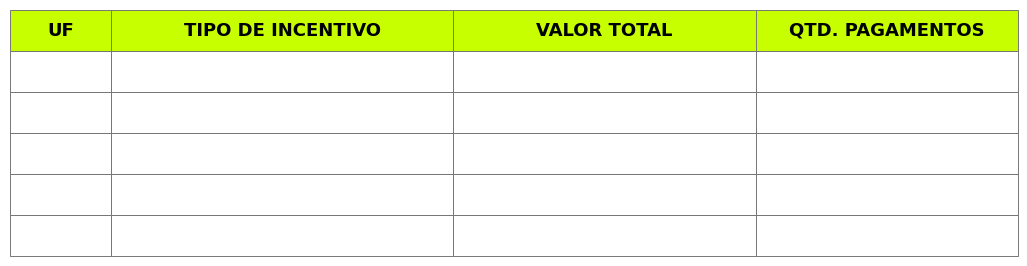

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import matplotlib.pyplot as plt
from google.colab import files

# Dados reais de março de 2024, já tratados
tabela = dfs2024["mar24"].head(5).copy()

# Formatação dos valores
tabela["VALOR_TOTAL"] = tabela["VALOR_TOTAL"].apply(
    lambda x: f"R$ {x:,.2f}".replace(",", "X")
    .replace(".", ",").replace("X", ".")
)

tabela["QUANTIDADE_PAGAMENTOS"] = (
    tabela["QUANTIDADE_PAGAMENTOS"]
    .apply(lambda x: f"{x:,.0f}".replace(",", "."))
)

# Nomes para exibição
tabela.columns = [
    "UF",
    "TIPO DE INCENTIVO",
    "VALOR TOTAL",
    "QTD. PAGAMENTOS"
]

# Cores da apresentação
VERDE = "#C8FF00"
BRANCO = "#FFFFFF"
TRANSPARENTE = (0, 0, 0, 0)

fig, ax = plt.subplots(figsize=(13, 3.2))
fig.patch.set_alpha(0)
ax.set_axis_off()

tb = ax.table(
    cellText=tabela.values,
    colLabels=tabela.columns,
    colWidths=[0.10, 0.34, 0.30, 0.26],
    cellLoc="center",
    colLoc="center",
    bbox=[0, 0, 1, 1]
)

tb.auto_set_font_size(False)
tb.set_fontsize(13)

for (linha, coluna), celula in tb.get_celld().items():
    celula.set_edgecolor("#777777")
    celula.set_linewidth(0.7)

    if linha == 0:
        celula.set_facecolor(VERDE)
        celula.get_text().set_color("#000000")
        celula.get_text().set_weight("bold")
    else:
        celula.set_facecolor(TRANSPARENTE)
        celula.get_text().set_color(BRANCO)

arquivo = "pe_de_meia_marco_tratado.png"

plt.savefig(
    arquivo,
    dpi=300,
    transparent=True,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()
files.download(arquivo)